# France fiscal brief, 13 October 2026

French sovereign debt: the interest bill, the shortening stock, who bears the
rate risk, and what five 2027 political configurations do to it, set against
Redbox's own statistical benchmark.

This notebook is the executable form of the briefing note
`reports/briefing_FRA_AFT_2026-09/briefing_inline.html`. Run top to bottom, it

1. renders every chart from the flat files in `deliverables/` (plus the
   Eurostat debt history in `data/manual/`) with
   `ggfiscal.report.briefing_fra` (the descriptive charts and
   `key_figures.csv`) and `ggfiscal.report.briefing_fra_scenarios` (the
   register rolled forward under each scenario by `ggfiscal.debt.simulate`);
2. fills the note's template with the values `tools/build_briefing_fra.py`
   computes and shows each section in the note's order;
3. writes `briefing.html` and `briefing_inline.html`, so the published page is
   reproduced by this notebook.

The questions for the AFT (section 7 of the note and the "To ask the AFT"
boxes) are left out here; the HTML keeps them. Facts marked **[ext]** come
from outside Redbox and are listed in section 8. Scenario assumptions are in
the tables of section 5; decisions D-S18-001 to D-S18-003 in `DECISIONS.md`.

In [1]:
import io

import pandas as pd
from IPython.display import HTML, SVG, Image as Image_display, display
from PIL import Image

from ggfiscal.debt import simulate as sim
from ggfiscal.report import briefing_fra, briefing_fra_scenarios, france_brief

FIG = france_brief.BRIEF_DIR / "figures"
FIGS = briefing_fra_scenarios.render_all(FIG)     # scenarios_FRA.csv, decomposition, duration
FIGS.update(briefing_fra.render_all(FIG))         # descriptive charts, key_figures.csv
france_brief.clear_cache()


def show(key, colours=48, width=880):
    """Display a rendered PNG quantised to a small palette (D-S9-004: keep the
    notebook renderable on GitHub)."""
    im = Image.open(FIGS[key]).convert("RGB")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), Image.LANCZOS)
    small = im.quantize(colours, dither=Image.Dither.NONE)
    buf = io.BytesIO(); small.save(buf, format="PNG", optimize=True)
    display(Image_display(data=buf.getvalue()))


def section(sid):
    """One section of the note: text and tables as HTML, charts as images."""
    for kind, value in france_brief.chunks(sid):
        if kind == "fig":
            show(value)
        elif kind == "svg":
            display(SVG(value))
        else:
            display(HTML(value))


missing = set(france_brief.figures()) - set(FIGS)
assert not missing, missing
print(f"{len(FIGS)} charts rendered into {FIG.relative_to(sim.ROOT)}; "
      f"{len(france_brief.figures())} appear in the brief")

19 charts rendered into reports/briefing_FRA_AFT_2026-09/figures; 18 appear in the brief


## Bottom line and key figures

In [2]:
section("s0")

Key figure,Value,Context
"Register stock, 10 Sep 2026","€2,937bn","uplifted; AFT total €2,904bn at 31 Aug"
"Avg coupon, fixed stock",2.14%,vs 10y OAT ≈ 4.85% at today's spread
GG interest 2025 → 2030 (status quo),2.2 → 4.0%,€65bn → €136bn
OAT redemptions 2027 / 28 / 29,203 / 246 / 281,"€bn; 2025 was €198bn, 2015–2024 €140–170bn"
"OAT–Bund 10y, 11 Oct 2026",135 bp,Bloomberg; September 2026 avg 101 bp; 2021 avg 38 bp
Value at risk per 100 bp,€140bn,"4.6% of GDP, on €2,344bn of OATs"


## 1. Where the stock stands

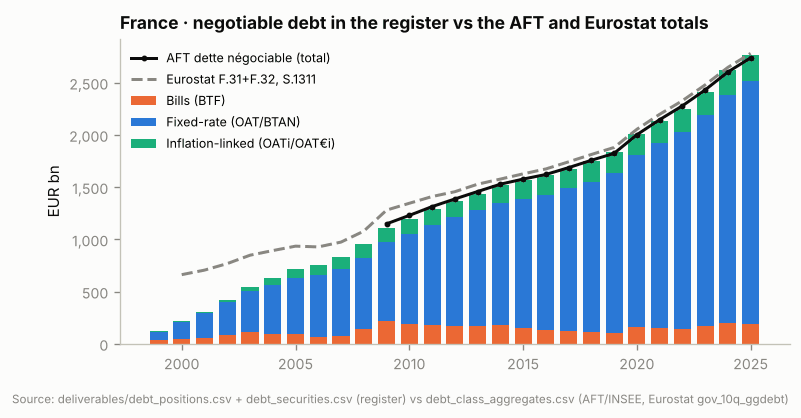

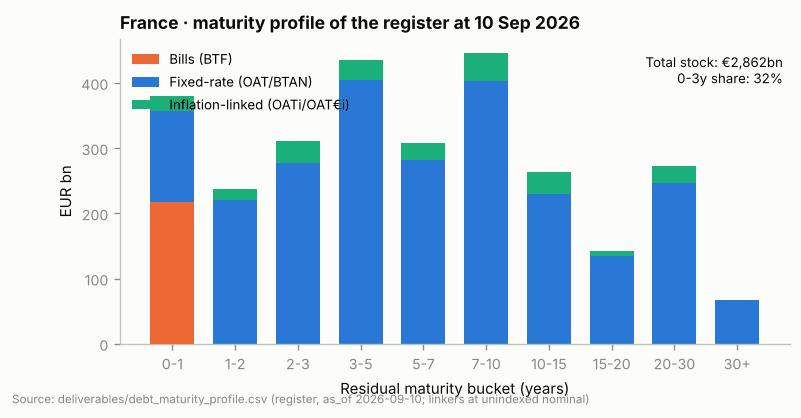

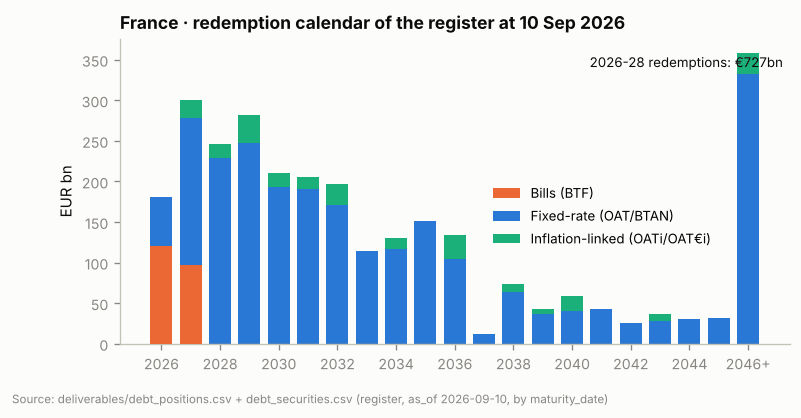

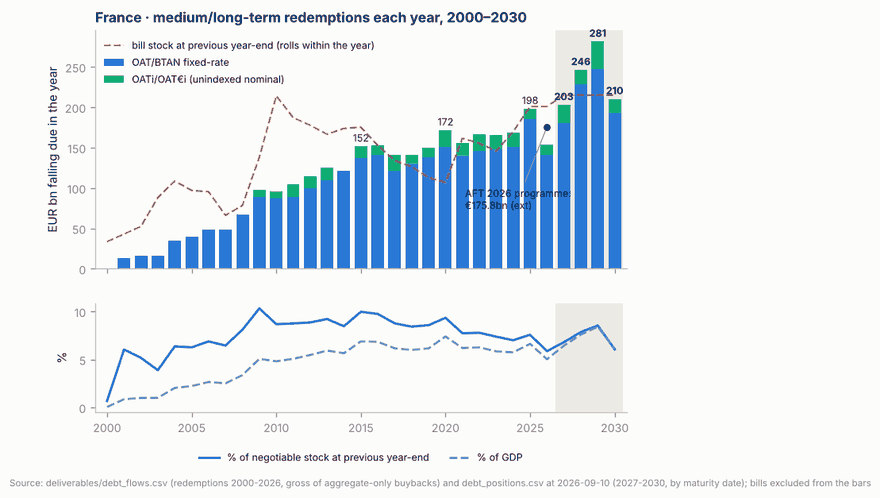

In [3]:
section("s1")

## 2. The interest bill and the wrong-way loop

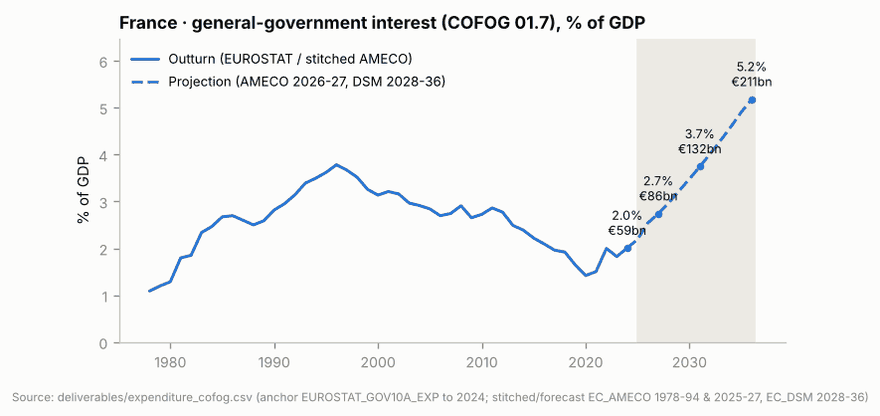

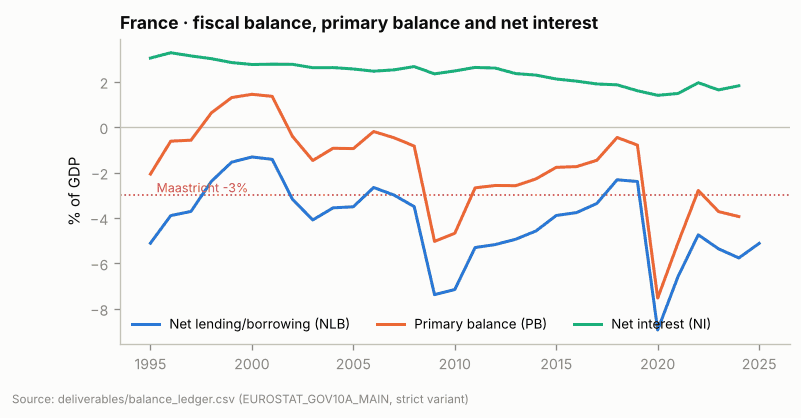

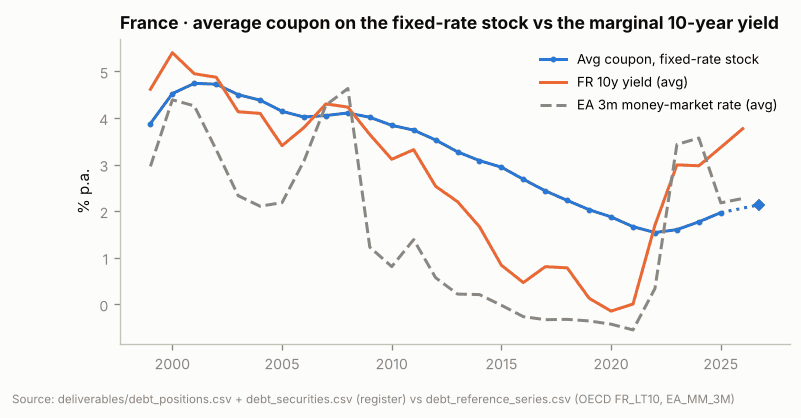

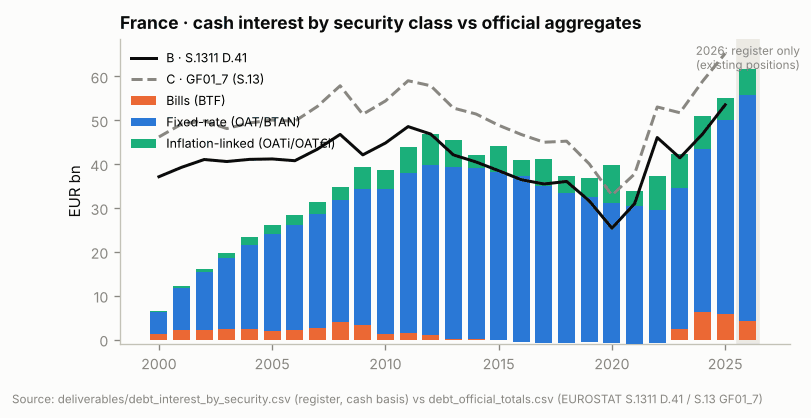

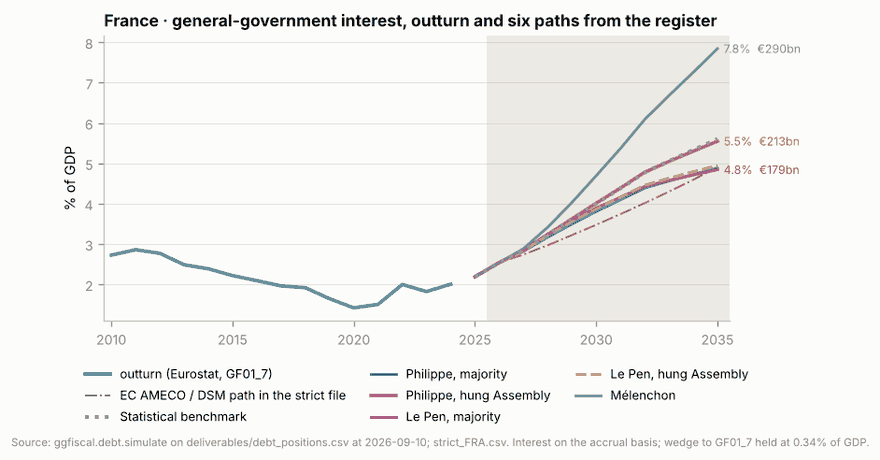

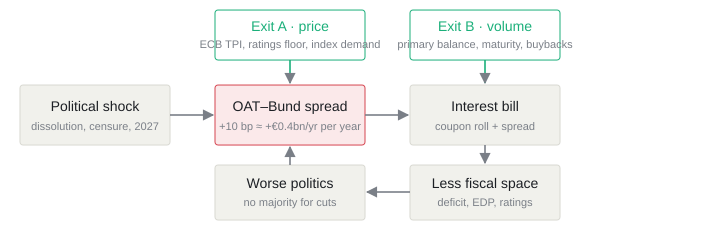

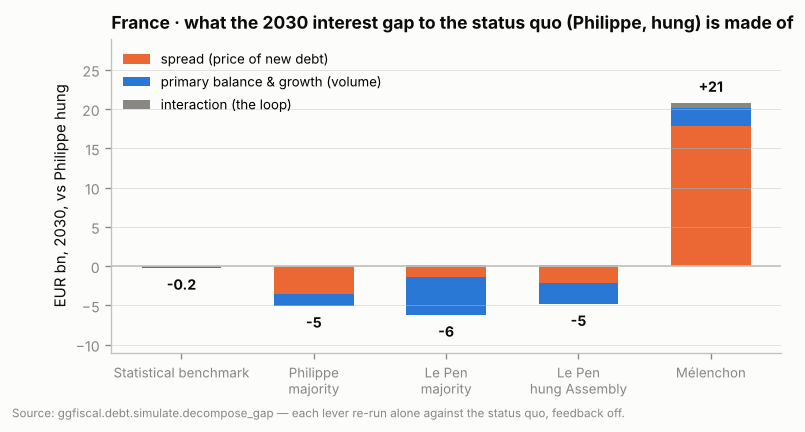

In [4]:
section("s2")

## 3. The shortening stock

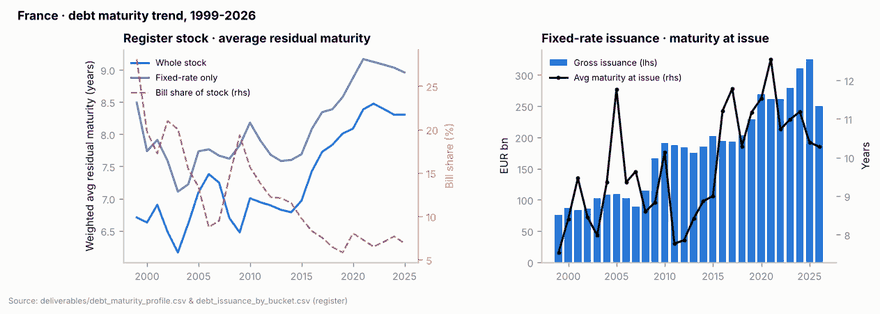

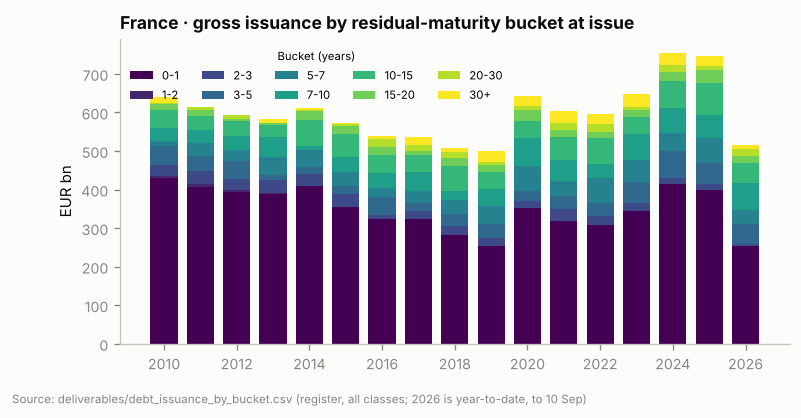

In [5]:
section("s3")

## 4. Who holds it, and how rate-sensitive they are

Holder (end-Q1 2026),Share of negotiable debt,≈ EUR bn,"MTM loss per 100 bp, EUR bn",Behaviour when rates rise
Non-residents,57.5%,"1,670",80,"About half euro-area. The non-euro half (Japan, Asian reserve managers) sold €30bn in 2024 and is the swing buyer now; the group that leaves first and returns last."
"Other French residents, incl. Banque de France (Eurosystem: €488bn at end-June 2026)",20.6%,598,29,"The Eurosystem is a passive seller: ≈€10bn a month of run-off, no reinvestment. The TPI is the only conditional buyer."
French banks,10.5%,305,15,"Mostly amortised cost, held for liquidity ratios; insensitive to mark-to-market, sensitive to ratings, repo haircuts and the sovereign-bank loop."
French insurers,9.6%,279,13,"Euro-fund books, long duration (above-average loss). Buy on inflows; inflows reverse with rates and with any assurance-vie or wealth-tax proposal."
French funds (OPCVM),1.8%,52,3,"Money-market funds in bills; price-insensitive, size-limited."


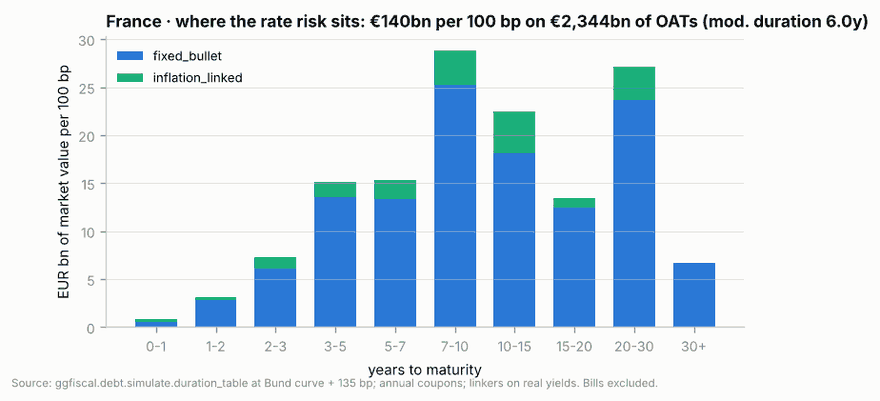

In [6]:
section("s4")

## 5. The 2027 map: Philippe, Le Pen, Mélenchon

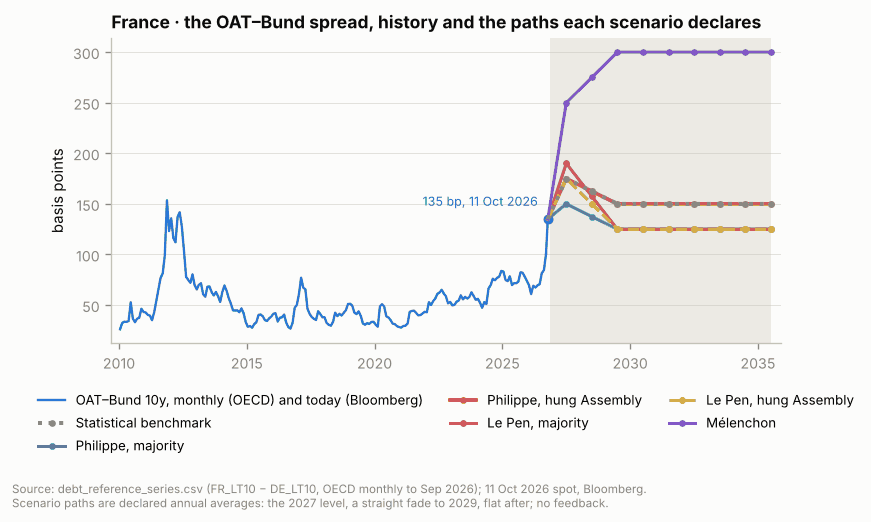

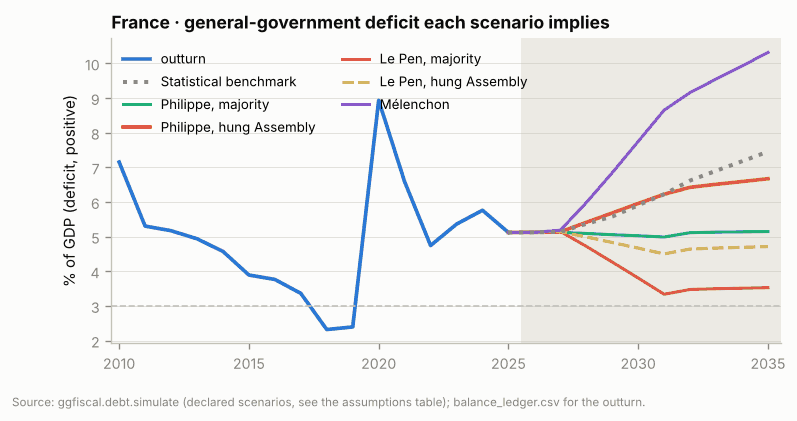

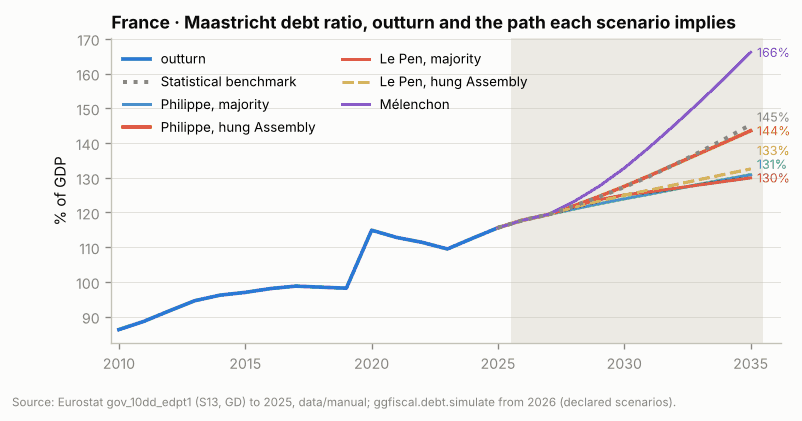

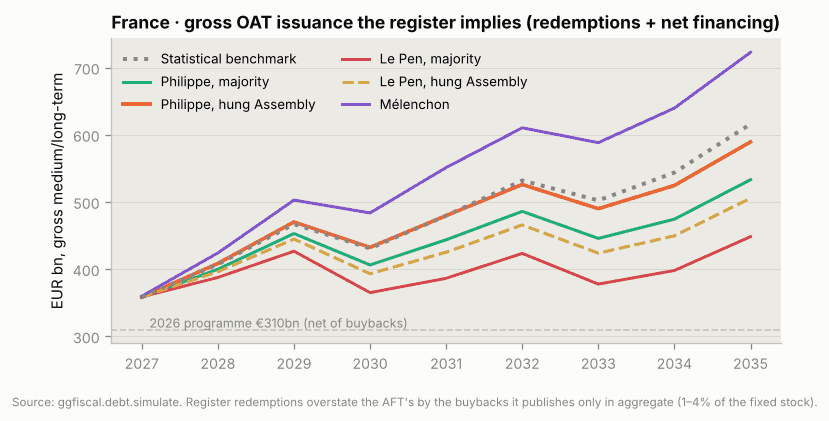

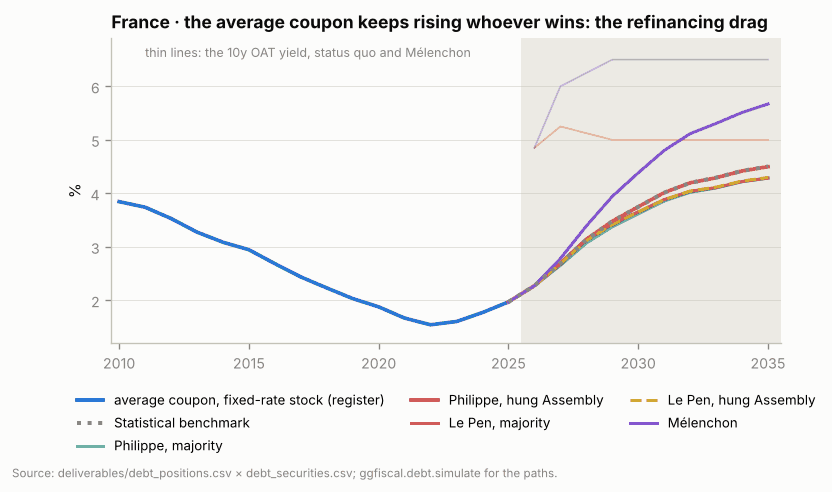

In [7]:
section("s5")

## 6. Other things that matter in the room

In [8]:
section("s6")

## 8. Method, sources and caveats

In [9]:
section("s8")

Item,Value,Source or reason
Register,"Positions at 10 Sep 2026, 106 bonds and 30 bill lines outstanding",debt_positions (office snapshot)
Nominal GDP,"2025 €2,979bn; 2026 €3,056bn; 2027 €3,151bn; then the scenario's real growth plus a 2% deflator",ledger; strict_FRA (EC AMECO); declared
Primary balance,"−3.1 (2025), −2.7 (2026), −2.5 (2027) % of GDP in every scenario; from 2028 the previous year in €bn plus the scenario's change, or for the statistical benchmark the benchmark's change in pp of GDP (section 5 tables)",declared; committee 11 Oct 2026
Bund curve,"3m 2.50, 2y 3.00, 5y 3.25, 10y 3.50, 30y 3.85 %, flat through 2035",10y declared by the committee (DE_LT10 Sep 2026 avg 3.47); 3m EA_MM_3M Aug 2026; 2y–30y keep the previous slope to the 10y
Spread today,"135 bp on 11 Oct 2026, applied to the rest of 2026 in every scenario",Bloomberg (ext); the bundle's OECD monthly series ends at 101 bp in September 2026
Spread term structure,0.15 / 0.45 / 0.75 / 1.00 / 1.15 × the 10y spread at 3m / 2y / 5y / 10y / 30y,declared
Issuance mix and bills,"AFT 2025 shares by bucket, with the AFT's own residual maturity at issue per bucket; bill stock €215bn; the same in every scenario",debt_issuance_by_bucket; AFT 2026 programme
Inflation (uplift),"2.0% a year, linkers 7% of new issuance at the real yield",declared
Deficit financed by negotiable debt,0.90,"Δ(F.31+F.32) / −NLB, 2015–2025, from the bundle"
Wedge to GF01_7,0.34% of GDP (€10.1bn in 2025),"GF01_7 less register cash interest, 2025"


## The scenario results as data

Every scenario-year the engine produced, at the years the note quotes.

In [10]:
res = pd.read_csv(FIG / "scenarios_FRA.csv")
cols = ["label", "year", "spread_bp", "oat_10y_pct", "primary_balance_pct", "gg_interest_bn",
        "gg_interest_pct_gdp", "deficit_pct_gdp", "debt_pct_gdp", "mlt_gross_issuance_bn"]
res[res.year.isin([2027, 2028, 2030, 2032, 2035])][cols].round(1).set_index(["label", "year"])

spread_bp  oat_10y_pct  primary_balance_pct  \
label                   year                                                
Statistical benchmark   2027      175.0          5.2                 -2.5   
                        2028      162.5          5.1                 -2.3   
                        2030      150.0          5.0                 -2.1   
                        2032      150.0          5.0                 -2.0   
                        2035      150.0          5.0                 -2.0   
Philippe, majority      2027      150.0          5.0                 -2.5   
                        2028      137.5          4.9                 -2.1   
                        2030      125.0          4.8                 -1.4   
                        2032      125.0          4.8                 -0.9   
                        2035      125.0          4.8                 -0.5   
Philippe, hung Assembly 2027      175.0          5.2                 -2.5   
                        2028      162.5          5.1                 -2.4   
                        2030      150.0          5.0                 -2.1   
                        2032      150.0          5.0                 -1.8   
                        2035      150.0          5.0                 -1.3   
Le Pen, majority        2027      190.0          5.4                 -2.5   
                        2028      157.5          5.1                 -1.7   
                        2030      125.0          4.8                 -0.1   
                        2032      125.0          4.8                  0.8   
                        2035      125.0          4.8                  1.1   
Le Pen, hung Assembly   2027      175.0          5.2                 -2.5   
                        2028      150.0          5.0                 -2.0   
                        2030      125.0          4.8                 -1.0   
                        2032      125.0          4.8                 -0.4   
                        2035      125.0          4.8                  0.0   
Mélenchon               2027      250.0          6.0                 -2.5   
                        2028      275.0          6.2                 -2.8   
                        2030      300.0          6.5                 -3.3   
                        2032      300.0          6.5                 -3.3   
                        2035      300.0          6.5                 -2.7   

                              gg_interest_bn  gg_interest_pct_gdp  \
label                   year                                        
Statistical benchmark   2027            89.4                  2.8   
                        2028           104.5                  3.2   
                        2030           136.0                  4.0   
                        2032           170.3                  4.8   
                        2035           215.4                  5.6   
Philippe, majority      2027            88.9                  2.8   
                        2028           103.0                  3.2   
                        2030           131.2                  3.8   
                        2032           160.5                  4.4   
                        2035           195.0                  4.9   
Philippe, hung Assembly 2027            89.4                  2.8   
                        2028           104.5                  3.2   
                        2030           136.2                  4.0   
                        2032           170.5                  4.8   
                        2035           213.2                  5.5   
Le Pen, majority        2027            89.7                  2.8   
                        2028           104.3                  3.2   
                        2030           130.2                  3.9   
                        2032           154.1                  4.4   
                        2035           178.8                  4.8   
Le Pen, hung Assembly   2027            89.4   

## Reproducing the HTML note

Writes `briefing.html` (figures by relative path) and `briefing_inline.html`
(figures embedded, the page that is published) from the template, the values
and the charts rendered above, and checks that every chart is embedded.

In [11]:
inline = france_brief.builder().main()
page = inline.read_text()
n_img = page.count('<img src="data:image/png;base64,')
assert "{{" not in page and n_img == len(france_brief.figures()), n_img
print(f"{inline.relative_to(sim.ROOT)}: {inline.stat().st_size / 1e6:.2f} MB, {n_img} charts embedded")

wrote /home/user/redbox/reports/briefing_FRA_AFT_2026-09/briefing.html and /home/user/redbox/reports/briefing_FRA_AFT_2026-09/briefing_inline.html (1.91 MB)
reports/briefing_FRA_AFT_2026-09/briefing_inline.html: 1.91 MB, 18 charts embedded
